--- Post-Midterm Performance Summary ---
 Midterm Year  6-Mo Return (%)  1-Yr Return (%)
         1950            14.16            16.51
         1954            16.03            30.33
         1958            10.17            10.17
         1962            19.83            24.44
         1966            15.20            12.55
         1970            23.22            10.64
         1974            18.60            17.84
         1978             5.98             7.83
         1982            18.07            18.95
         1986            20.01             1.88
         1990            21.47            24.74
         1994            12.61            25.91
         1998            19.91            21.97
         2002             0.53            14.90
         2006             8.90             6.65
         2010            12.88             2.07
         2014             3.77             4.48
         2018             4.57            11.97
         2022             7.90            13.56

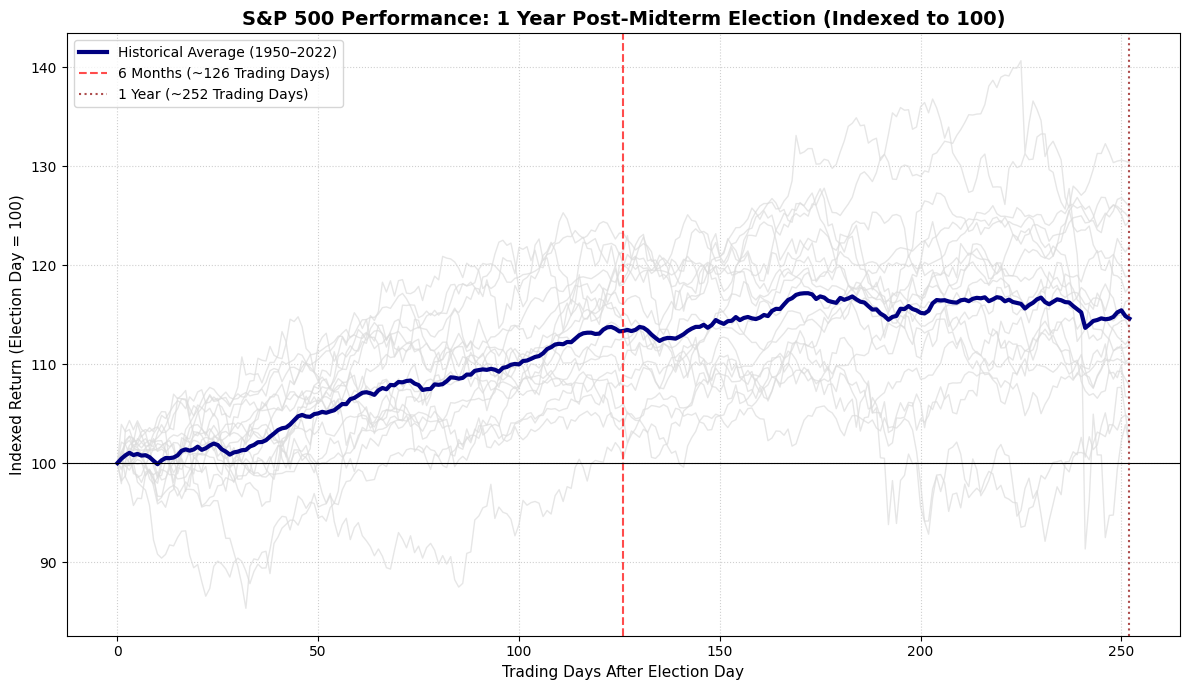

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

# Get S&P 500 daily data back to 1950
sp500 = yf.Ticker("^GSPC").history(period="max")
sp500.index = pd.to_datetime(sp500.index).tz_localize(None)

# Define midterm election dates
midterm_dates = {
    1950: "1950-11-07", 1954: "1954-11-02", 1958: "1958-11-04",
    1962: "1962-11-06", 1966: "1966-11-08", 1970: "1970-11-03",
    1974: "1974-11-05", 1978: "1978-11-07", 1982: "1982-11-02",
    1986: "1986-11-04", 1990: "1990-11-06", 1994: "1994-11-08",
    1998: "1998-11-03", 2002: "2002-11-05", 2006: "2006-11-07",
    2010: "2010-11-02", 2014: "2014-11-04", 2018: "2018-11-06",
    2022: "2022-11-08"
}

trading_days_6m = 126  # ~6 months of trading days
trading_days_1y = 252  # ~12 months of trading days

trajectories = {}

# 1-year indexed growth for each cycle
for year, date_str in midterm_dates.items():
    election_dt = pd.to_datetime(date_str)
    
    # Locate exact or next closest trading day
    sub = sp500[sp500.index >= election_dt]
    if len(sub) >= trading_days_1y:
        prices = sub['Close'].iloc[:trading_days_1y + 1].values
        # Index to 100 on Election Day
        indexed_prices = (prices / prices[0]) * 100
        trajectories[year] = indexed_prices

df_traj = pd.DataFrame(trajectories)

# Compute 6-Month and 1-Year summary statistics
results = []
for year in df_traj.columns:
    pct_6m = df_traj[year].iloc[trading_days_6m] - 100
    pct_1y = df_traj[year].iloc[-1] - 100
    results.append({"Midterm Year": year, "6-Mo Return (%)": round(pct_6m, 2), "1-Yr Return (%)": round(pct_1y, 2)})

df_summary = pd.DataFrame(results)
print("--- Post-Midterm Performance Summary ---")
print(df_summary.to_string(index=False))
print(f"\nAverage 6-Month Post-Midterm Return: {df_summary['6-Mo Return (%)'].mean():.2f}%")
print(f"Average 1-Year Post-Midterm Return:  {df_summary['1-Yr Return (%)'].mean():.2f}%")

# Plot
plt.figure(figsize=(12, 7))

# Add individual midterm lines
for year in df_traj.columns:
    plt.plot(df_traj.index, df_traj[year], color='gainsboro', linewidth=1, alpha=0.7)

# Average Trajectory
avg_trajectory = df_traj.mean(axis=1)
plt.plot(avg_trajectory.index, avg_trajectory, color='navy', linewidth=3, label='Historical Average (1950–2022)')

# markers for 6-Month and 1-Year marks
plt.axvline(x=trading_days_6m, color='red', linestyle='--', alpha=0.7, label='6 Months (~126 Trading Days)')
plt.axvline(x=trading_days_1y, color='darkred', linestyle=':', alpha=0.7, label='1 Year (~252 Trading Days)')
plt.axhline(y=100, color='black', linestyle='-', linewidth=0.8)

plt.title("S&P 500 Performance: 1 Year Post-Midterm Election (Indexed to 100)", fontsize=14, fontweight='bold')
plt.xlabel("Trading Days After Election Day", fontsize=11)
plt.ylabel("Indexed Return (Election Day = 100)", fontsize=11)
plt.legend(loc="upper left")
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [4]:
import pandas as pd
import numpy as np
import yfinance as yf
import plotly.graph_objects as go
import plotly.io as pio

# Renderer Setup (Fixes blank cell issue in Jupyter / VS Code)
pio.renderers.default = "notebook_connected"


# Get S&P 500 Historical Data
print("Fetching S&P 500 data from Yahoo Finance...")
sp500 = yf.Ticker("^GSPC").history(period="max")
sp500.index = pd.to_datetime(sp500.index).tz_localize(None)

# Define Midterm Election Dates
midterm_dates = {
    1950: "1950-11-07", 1954: "1954-11-02", 1958: "1958-11-04",
    1962: "1962-11-06", 1966: "1966-11-08", 1970: "1970-11-03",
    1974: "1974-11-05", 1978: "1978-11-07", 1982: "1982-11-02",
    1986: "1986-11-04", 1990: "1990-11-06", 1994: "1994-11-08",
    1998: "1998-11-03", 2002: "2002-11-05", 2006: "2006-11-07",
    2010: "2010-11-02", 2014: "2014-11-04", 2018: "2018-11-06",
    2022: "2022-11-08"
}

trading_days_6m = 126  # ~6 months of trading days
trading_days_1y = 252  # ~1 year of trading days
df_traj = pd.DataFrame()


# 1-Year Indexed Trajectories (Election Day = 100)
for year, date_str in midterm_dates.items():
    election_dt = pd.to_datetime(date_str)
    sub = sp500[sp500.index >= election_dt]
    if len(sub) >= trading_days_1y:
        prices = sub['Close'].iloc[:trading_days_1y + 1].values
        indexed_prices = (prices / prices[0]) * 100
        df_traj[year] = indexed_prices


# Interactive Plotly Visualization
fig = go.Figure()

# Add individual midterm trajectories
for year in df_traj.columns:
    series = df_traj[year]
    pct_return = (series - 100).round(2)
    ret_6m = pct_return.iloc[trading_days_6m]
    ret_1y = pct_return.iloc[-1]
    
    # Multi-column hover matrix: [daily_return, 6m_return, 1y_return]
    custom_data = np.column_stack([
        pct_return,
        np.full(len(pct_return), ret_6m),
        np.full(len(pct_return), ret_1y)
    ])
    
    fig.add_trace(go.Scatter(
        x=series.index,
        y=series.round(2),
        mode='lines',
        name=str(year),
        opacity=0.6,
        hovertemplate=(
            f"<b>Midterm Year: {year}</b><br>"
            "Trading Day: %{x}<br>"
            "Indexed Price: %{y:.2f}<br>"
            "Current Day Return: %{customdata[0]:+.2f}%<br>"
            "<b>6-Mo Final Return: %{customdata[1]:+.2f}%</b><br>"
            "<b>1-Yr Final Return: %{customdata[2]:+.2f}%</b>"
            "<extra></extra>"
        ),
        customdata=custom_data
    ))

# Add Historical Average Trajectory
avg_traj = df_traj.mean(axis=1)
avg_pct = (avg_traj - 100).round(2)
avg_6m = avg_pct.iloc[trading_days_6m]
avg_1y = avg_pct.iloc[-1]

avg_custom_data = np.column_stack([
    avg_pct,
    np.full(len(avg_pct), avg_6m),
    np.full(len(avg_pct), avg_1y)
])

fig.add_trace(go.Scatter(
    x=avg_traj.index,
    y=avg_traj.round(2),
    mode='lines',
    name='Historical Average',
    line=dict(color='navy', width=4),
    hovertemplate=(
        "<b>HISTORICAL AVERAGE</b><br>"
        "Trading Day: %{x}<br>"
        "Indexed Price: %{y:.2f}<br>"
        "Current Day Return: %{customdata[0]:+.2f}%<br>"
        "<b>6-Mo Avg Return: %{customdata[1]:+.2f}%</b><br>"
        "<b>1-Yr Avg Return: %{customdata[2]:+.2f}%</b>"
        "<extra></extra>"
    ),
    customdata=avg_custom_data
))

# Add reference lines & formatting
fig.add_vline(x=trading_days_6m, line_dash="dash", line_color="crimson", annotation_text="6 Months (~Day 126)")
fig.add_hline(y=100, line_dash="solid", line_color="black", line_width=1)

fig.update_layout(
    title="<b>S&P 500 Performance: 1 Year Post-Midterm Election (1950–2022)</b>",
    xaxis_title="Trading Days After Election Day",
    yaxis_title="Indexed Value (Election Day = 100)",
    hovermode="closest",
    template="plotly_white",
    legend_title="Click Year to Toggle",
    height=650
)

# Save to standalone HTML file (opens interactive plot in any browser)
output_filename = "midterm_sp500_analysis.html"
fig.write_html(output_filename)
print(f"Interactive plot exported locally to: {output_filename}")

fig.show()

Fetching S&P 500 data from Yahoo Finance...
Interactive plot exported locally to: midterm_sp500_analysis.html


In [5]:
import pandas as pd
import numpy as np
import yfinance as yf
import plotly.graph_objects as go
import plotly.io as pio

# Renderer Setup (Fixes blank cell issue in Jupyter / VS Code)
pio.renderers.default = "notebook_connected"


# Get NASDAQ-100 Historical Data
print("Fetching NASDAQ-100 (^NDX) data from Yahoo Finance...")
ndx = yf.Ticker("^NDX").history(period="max")
ndx.index = pd.to_datetime(ndx.index).tz_localize(None)


# Define Midterm Election Dates (1986 - 2022)
midterm_dates = {
    1986: "1986-11-04", 1990: "1990-11-06", 1994: "1994-11-08",
    1998: "1998-11-03", 2002: "2002-11-05", 2006: "2006-11-07",
    2010: "2010-11-02", 2014: "2014-11-04", 2018: "2018-11-06",
    2022: "2022-11-08"
}

trading_days_6m = 126  # ~6 months of trading days
trading_days_1y = 252  # ~1 year of trading days
df_traj = pd.DataFrame()


# 1-Year Indexed Trajectories (Election Day = 100)
for year, date_str in midterm_dates.items():
    election_dt = pd.to_datetime(date_str)
    sub = ndx[ndx.index >= election_dt]
    if len(sub) >= trading_days_1y:
        prices = sub['Close'].iloc[:trading_days_1y + 1].values
        indexed_prices = (prices / prices[0]) * 100
        df_traj[year] = indexed_prices


# Build Interactive Plotly Visualization
fig = go.Figure()

# Add individual midterm trajectories
for year in df_traj.columns:
    series = df_traj[year]
    pct_return = (series - 100).round(2)
    ret_6m = pct_return.iloc[trading_days_6m]
    ret_1y = pct_return.iloc[-1]
    
    # Custom hover matrix: [daily_return, 6m_return, 1y_return]
    custom_data = np.column_stack([
        pct_return,
        np.full(len(pct_return), ret_6m),
        np.full(len(pct_return), ret_1y)
    ])
    
    fig.add_trace(go.Scatter(
        x=series.index,
        y=series.round(2),
        mode='lines',
        name=str(year),
        opacity=0.6,
        hovertemplate=(
            f"<b>Midterm Year: {year}</b><br>"
            "Trading Day: %{x}<br>"
            "Indexed Price: %{y:.2f}<br>"
            "Current Day Return: %{customdata[0]:+.2f}%<br>"
            "<b>6-Mo Final Return: %{customdata[1]:+.2f}%</b><br>"
            "<b>1-Yr Final Return: %{customdata[2]:+.2f}%</b>"
            "<extra></extra>"
        ),
        customdata=custom_data
    ))

# Add Historical Average Trajectory
avg_traj = df_traj.mean(axis=1)
avg_pct = (avg_traj - 100).round(2)
avg_6m = avg_pct.iloc[trading_days_6m]
avg_1y = avg_pct.iloc[-1]

avg_custom_data = np.column_stack([
    avg_pct,
    np.full(len(avg_pct), avg_6m),
    np.full(len(avg_pct), avg_1y)
])

fig.add_trace(go.Scatter(
    x=avg_traj.index,
    y=avg_traj.round(2),
    mode='lines',
    name='Historical Average',
    line=dict(color='darkgreen', width=4),
    hovertemplate=(
        "<b>HISTORICAL AVERAGE</b><br>"
        "Trading Day: %{x}<br>"
        "Indexed Price: %{y:.2f}<br>"
        "Current Day Return: %{customdata[0]:+.2f}%<br>"
        "<b>6-Mo Avg Return: %{customdata[1]:+.2f}%</b><br>"
        "<b>1-Yr Avg Return: %{customdata[2]:+.2f}%</b>"
        "<extra></extra>"
    ),
    customdata=avg_custom_data
))

# Add reference lines & formatting
fig.add_vline(x=trading_days_6m, line_dash="dash", line_color="crimson", annotation_text="6 Months (~Day 126)")
fig.add_hline(y=100, line_dash="solid", line_color="black", line_width=1)

fig.update_layout(
    title="<b>NASDAQ-100 (^NDX) Performance: 1 Year Post-Midterm Election (1986–2022)</b>",
    xaxis_title="Trading Days After Election Day",
    yaxis_title="Indexed Value (Election Day = 100)",
    hovermode="closest",
    template="plotly_white",
    legend_title="Click Year to Toggle",
    height=650
)

# Export standalone HTML file
output_filename = "nasdaq100_midterm_analysis.html"
fig.write_html(output_filename)
print(f"Interactive plot exported locally to: {output_filename}")

# Display plot in notebook
fig.show()

Fetching NASDAQ-100 (^NDX) data from Yahoo Finance...
Interactive plot exported locally to: nasdaq100_midterm_analysis.html


In [6]:
import pandas as pd
import numpy as np
import yfinance as yf
import plotly.graph_objects as go
import plotly.io as pio

# Renderer Setup
pio.renderers.default = "notebook_connected"

# Get Russell 2000 Historical Data
print("Fetching Russell 2000 (^RUT) data from Yahoo Finance...")
rut = yf.Ticker("^RUT").history(period="max")
rut.index = pd.to_datetime(rut.index).tz_localize(None)

# Define Midterm Election Dates (1990 - 2022)
midterm_dates = {
    1990: "1990-11-06", 1994: "1994-11-08", 1998: "1998-11-03",
    2002: "2002-11-05", 2006: "2006-11-07", 2010: "2010-11-02",
    2014: "2014-11-04", 2018: "2018-11-06", 2022: "2022-11-08"
}

trading_days_6m = 126
trading_days_1y = 252
df_traj = pd.DataFrame()

# 1-Year Indexed Trajectories (Election Day = 100)
for year, date_str in midterm_dates.items():
    election_dt = pd.to_datetime(date_str)
    sub = rut[rut.index >= election_dt]
    if len(sub) >= trading_days_1y:
        prices = sub['Close'].iloc[:trading_days_1y + 1].values
        indexed_prices = (prices / prices[0]) * 100
        df_traj[year] = indexed_prices

# Build Interactive Plotly Visualization
fig = go.Figure()

for year in df_traj.columns:
    series = df_traj[year]
    pct_return = (series - 100).round(2)
    ret_6m = pct_return.iloc[trading_days_6m]
    ret_1y = pct_return.iloc[-1]
    
    custom_data = np.column_stack([
        pct_return,
        np.full(len(pct_return), ret_6m),
        np.full(len(pct_return), ret_1y)
    ])
    
    fig.add_trace(go.Scatter(
        x=series.index,
        y=series.round(2),
        mode='lines',
        name=str(year),
        opacity=0.6,
        hovertemplate=(
            f"<b>Midterm Year: {year}</b><br>"
            "Trading Day: %{x}<br>"
            "Indexed Price: %{y:.2f}<br>"
            "Current Day Return: %{customdata[0]:+.2f}%<br>"
            "<b>6-Mo Final Return: %{customdata[1]:+.2f}%</b><br>"
            "<b>1-Yr Final Return: %{customdata[2]:+.2f}%</b>"
            "<extra></extra>"
        ),
        customdata=custom_data
    ))

# Add Historical Average Trajectory
avg_traj = df_traj.mean(axis=1)
avg_pct = (avg_traj - 100).round(2)
avg_6m = avg_pct.iloc[trading_days_6m]
avg_1y = avg_pct.iloc[-1]

avg_custom_data = np.column_stack([
    avg_pct,
    np.full(len(avg_pct), avg_6m),
    np.full(len(avg_pct), avg_1y)
])

fig.add_trace(go.Scatter(
    x=avg_traj.index,
    y=avg_traj.round(2),
    mode='lines',
    name='Historical Average',
    line=dict(color='purple', width=4),
    hovertemplate=(
        "<b>HISTORICAL AVERAGE</b><br>"
        "Trading Day: %{x}<br>"
        "Indexed Price: %{y:.2f}<br>"
        "Current Day Return: %{customdata[0]:+.2f}%<br>"
        "<b>6-Mo Avg Return: %{customdata[1]:+.2f}%</b><br>"
        "<b>1-Yr Avg Return: %{customdata[2]:+.2f}%</b>"
        "<extra></extra>"
    ),
    customdata=avg_custom_data
))

fig.add_vline(x=trading_days_6m, line_dash="dash", line_color="crimson", annotation_text="6 Months (~Day 126)")
fig.add_hline(y=100, line_dash="solid", line_color="black", line_width=1)

fig.update_layout(
    title="<b>Russell 2000 Small-Cap (^RUT) Performance: 1 Year Post-Midterm (1990–2022)</b>",
    xaxis_title="Trading Days After Election Day",
    yaxis_title="Indexed Value (Election Day = 100)",
    hovermode="closest",
    template="plotly_white",
    legend_title="Click Year to Toggle",
    height=650
)

fig.write_html("russell2000_midterm_analysis.html")
print("Exported: russell2000_midterm_analysis.html")
fig.show()

Fetching Russell 2000 (^RUT) data from Yahoo Finance...
Exported: russell2000_midterm_analysis.html


In [7]:
import pandas as pd
import numpy as np
import yfinance as yf
import plotly.graph_objects as go
import plotly.io as pio

# Renderer Setup
pio.renderers.default = "notebook_connected"

# Fetch S&P MidCap 400 Historical Data
print("Fetching S&P MidCap 400 (^MID) data from Yahoo Finance...")
mid = yf.Ticker("^MID").history(period="max")
mid.index = pd.to_datetime(mid.index).tz_localize(None)

# Define Midterm Election Dates (1994 - 2022)
midterm_dates = {
    1994: "1994-11-08", 1998: "1998-11-03", 2002: "2002-11-05",
    2006: "2006-11-07", 2010: "2010-11-02", 2014: "2014-11-04",
    2018: "2018-11-06", 2022: "2022-11-08"
}

trading_days_6m = 126
trading_days_1y = 252
df_traj = pd.DataFrame()

# 1-Year Indexed Trajectories (Election Day = 100)
for year, date_str in midterm_dates.items():
    election_dt = pd.to_datetime(date_str)
    sub = mid[mid.index >= election_dt]
    if len(sub) >= trading_days_1y:
        prices = sub['Close'].iloc[:trading_days_1y + 1].values
        indexed_prices = (prices / prices[0]) * 100
        df_traj[year] = indexed_prices

# Build Interactive Plotly Visualization
fig = go.Figure()

for year in df_traj.columns:
    series = df_traj[year]
    pct_return = (series - 100).round(2)
    ret_6m = pct_return.iloc[trading_days_6m]
    ret_1y = pct_return.iloc[-1]
    
    custom_data = np.column_stack([
        pct_return,
        np.full(len(pct_return), ret_6m),
        np.full(len(pct_return), ret_1y)
    ])
    
    fig.add_trace(go.Scatter(
        x=series.index,
        y=series.round(2),
        mode='lines',
        name=str(year),
        opacity=0.6,
        hovertemplate=(
            f"<b>Midterm Year: {year}</b><br>"
            "Trading Day: %{x}<br>"
            "Indexed Price: %{y:.2f}<br>"
            "Current Day Return: %{customdata[0]:+.2f}%<br>"
            "<b>6-Mo Final Return: %{customdata[1]:+.2f}%</b><br>"
            "<b>1-Yr Final Return: %{customdata[2]:+.2f}%</b>"
            "<extra></extra>"
        ),
        customdata=custom_data
    ))

# Add Historical Average Trajectory
avg_traj = df_traj.mean(axis=1)
avg_pct = (avg_traj - 100).round(2)
avg_6m = avg_pct.iloc[trading_days_6m]
avg_1y = avg_pct.iloc[-1]

avg_custom_data = np.column_stack([
    avg_pct,
    np.full(len(avg_pct), avg_6m),
    np.full(len(avg_pct), avg_1y)
])

fig.add_trace(go.Scatter(
    x=avg_traj.index,
    y=avg_traj.round(2),
    mode='lines',
    name='Historical Average',
    line=dict(color='darkorange', width=4),
    hovertemplate=(
        "<b>HISTORICAL AVERAGE</b><br>"
        "Trading Day: %{x}<br>"
        "Indexed Price: %{y:.2f}<br>"
        "Current Day Return: %{customdata[0]:+.2f}%<br>"
        "<b>6-Mo Avg Return: %{customdata[1]:+.2f}%</b><br>"
        "<b>1-Yr Avg Return: %{customdata[2]:+.2f}%</b>"
        "<extra></extra>"
    ),
    customdata=avg_custom_data
))

fig.add_vline(x=trading_days_6m, line_dash="dash", line_color="crimson", annotation_text="6 Months (~Day 126)")
fig.add_hline(y=100, line_dash="solid", line_color="black", line_width=1)

fig.update_layout(
    title="<b>S&P MidCap 400 (^MID) Performance: 1 Year Post-Midterm (1994–2022)</b>",
    xaxis_title="Trading Days After Election Day",
    yaxis_title="Indexed Value (Election Day = 100)",
    hovermode="closest",
    template="plotly_white",
    legend_title="Click Year to Toggle",
    height=650
)

fig.write_html("sp400_midcap_midterm_analysis.html")
print("Exported: sp400_midcap_midterm_analysis.html")
fig.show()

Fetching S&P MidCap 400 (^MID) data from Yahoo Finance...
Exported: sp400_midcap_midterm_analysis.html
